# 01 · Raw whole-FOV fluorescence and baseline sensitivity

This notebook answers Sarah's questions for one recording:
1. **Raw F before ΔF/F**: the whole-FOV mean over the valid crop, with the start-to-end change (bleaching/drift).
2. **Baselines**: the current rolling F₀ against fixed full-recording low percentiles and much longer rolling windows.
3. **Are slow fluctuations preserved?** The correlation and 5–95% amplitude ratio of each method's slow component (rolling mean over `SLOW_TIMESCALE_S`), compared with the current method.
4. **Are relative ΔF/F amplitudes preserved?** In each contiguous block of the recording, the gain of each method's fast component on the current method's. A flat line across blocks means transients keep their relative sizes.

A fixed F₀ keeps bleaching and drift as well as biological slow fluctuations, so read it together with the raw-F drift in panel 1. For multi-plane recordings this runs on each plane separately.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nlight import plotting, session, suite2p_io, workflows

plotting.use_lab_style()
RECORDINGS = session.load_recordings(Path('../../configs/nlight_recordings.json'))
print('Available:', list(RECORDINGS))

Available: ['corridor2 passive viewing', 'corridor2 baseline', 'passive (4 planes)', 'no puff (2x, 4 planes)', 'puff (2x, 4 planes)']


In [2]:
RECORDING = 'corridor2 passive viewing'
FIXED_PERCENTILES = (5, 10)
LONG_WINDOWS_S = (180, 300, 600)
SLOW_TIMESCALE_S = 10      # try 20-30 s for arousal-scale fluctuations
N_BLOCKS = 5

/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 563 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")


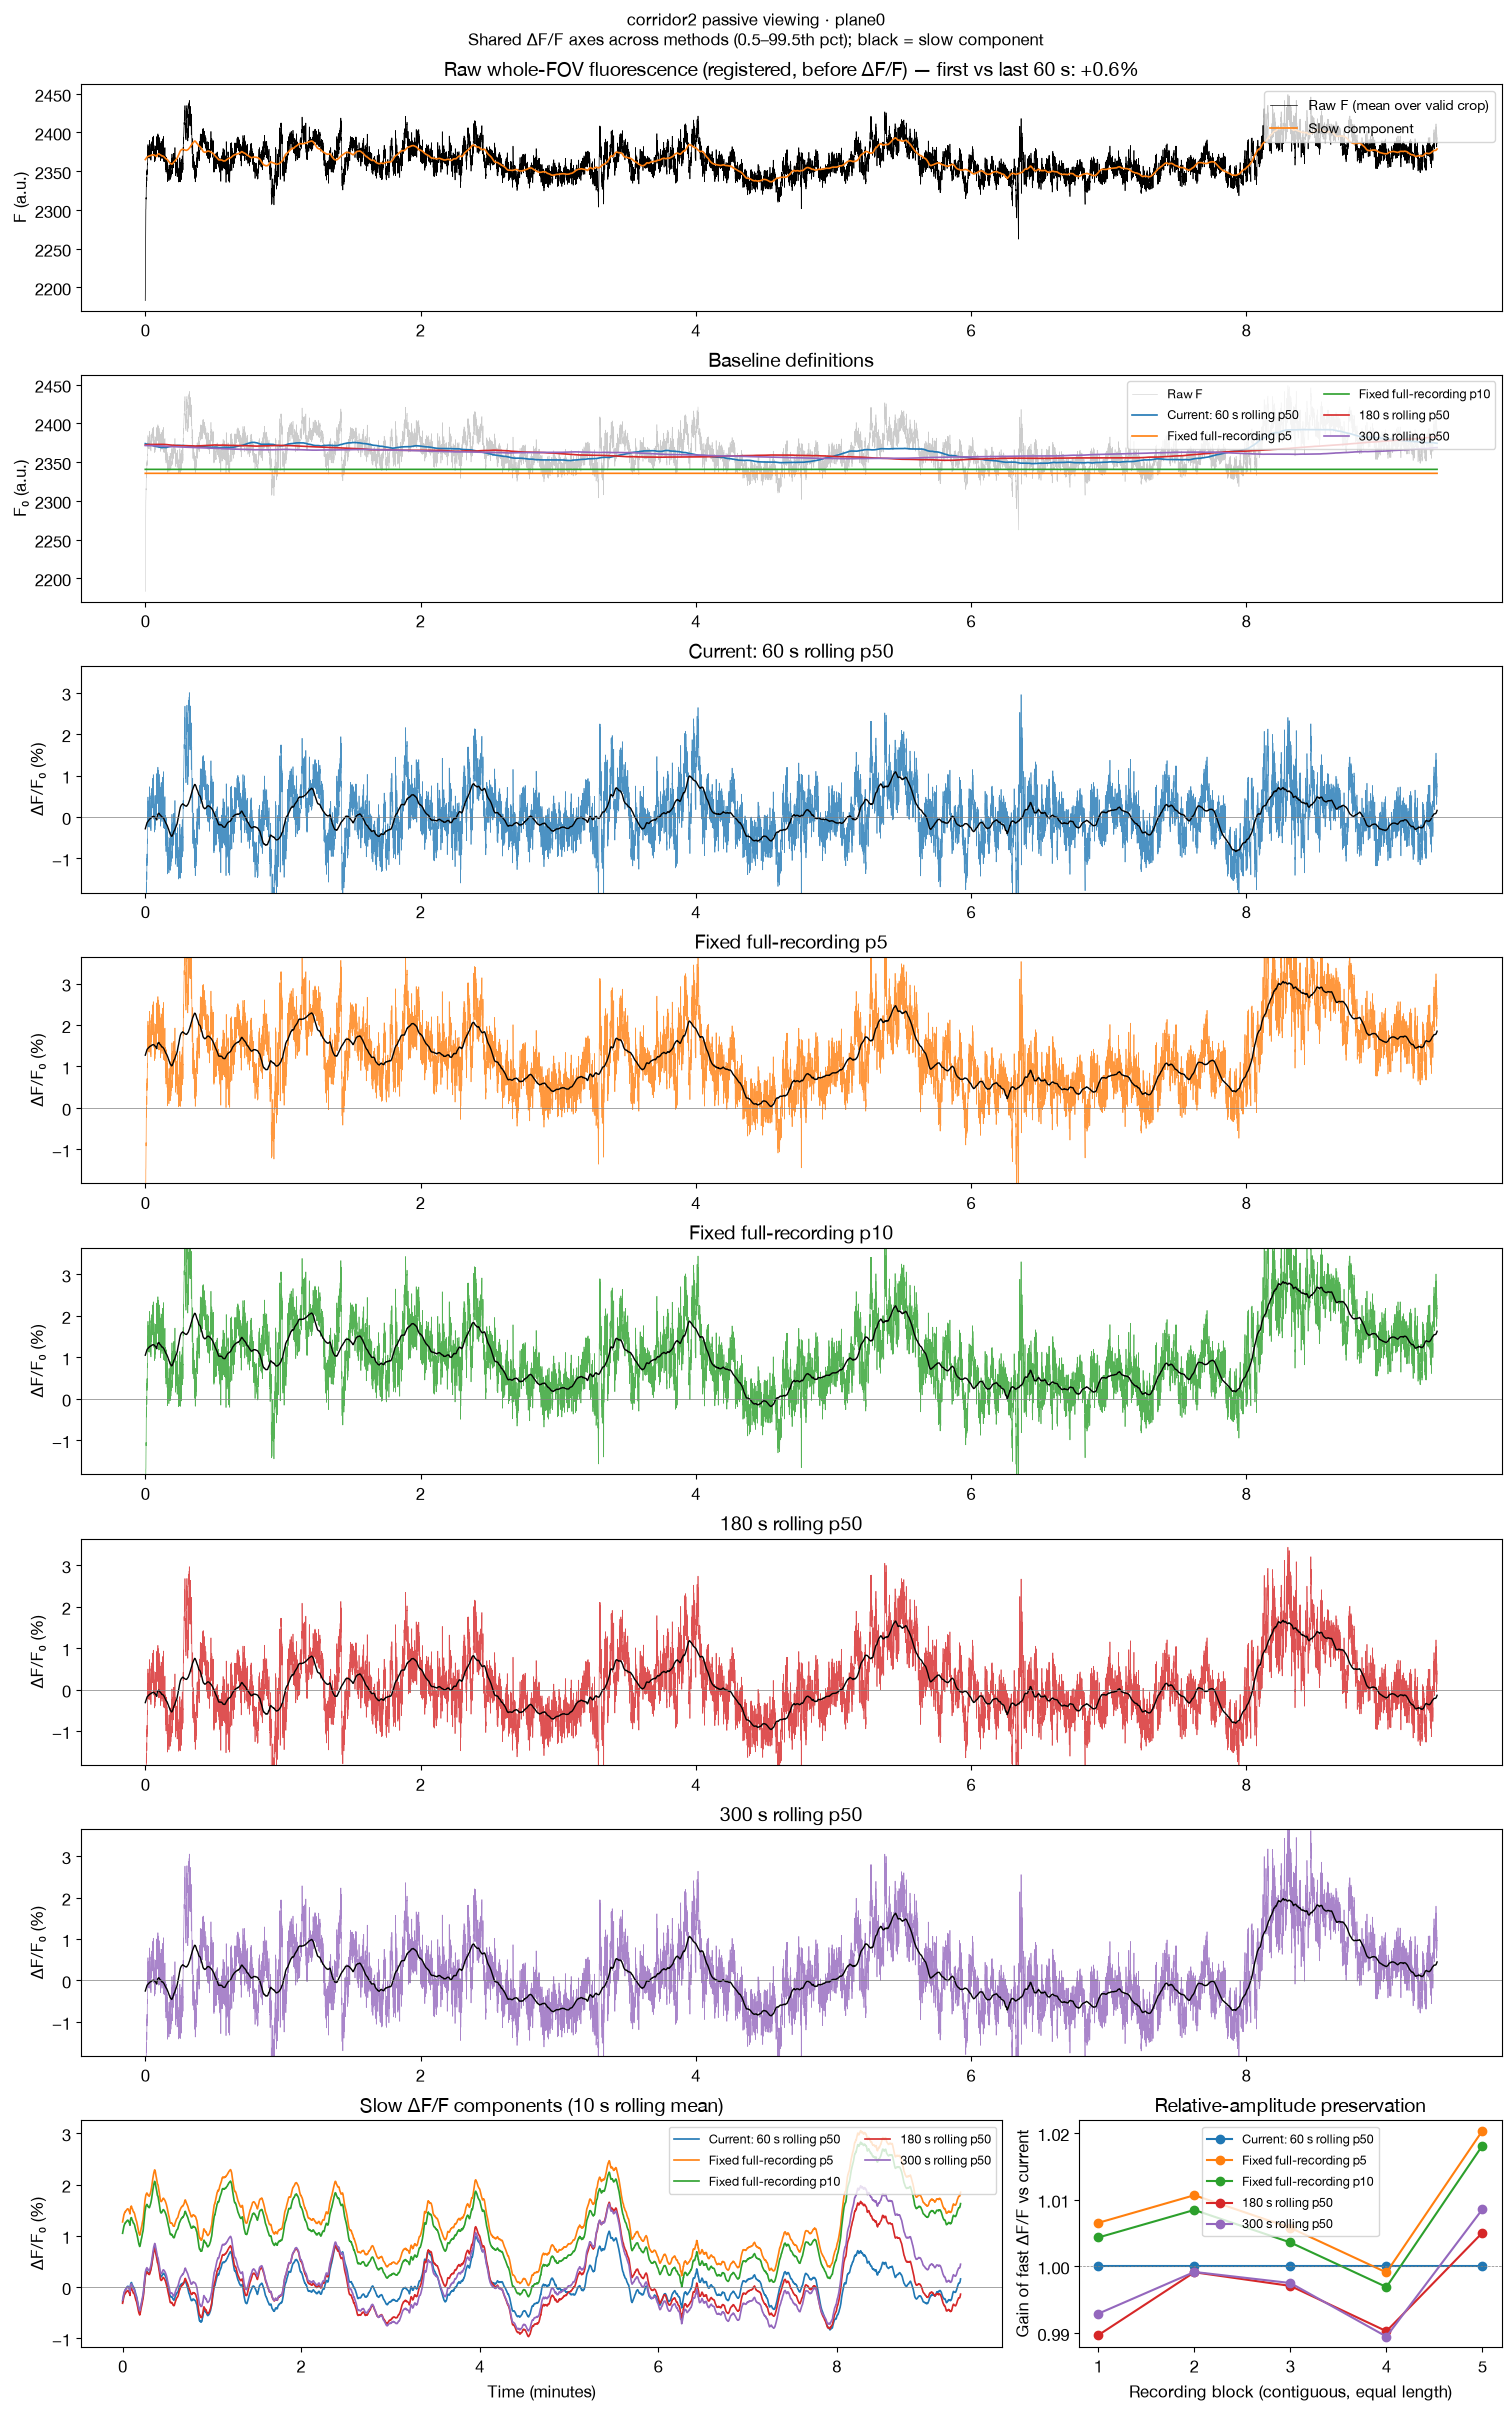

{'first_s': 60.0, 'F_start': 2369.2377583150587, 'F_end': 2384.298390029896, 'percent_change': 0.6356741387385256}


,median_dff_pct,p5_to_p95_pp,slow_p5_to_p95_pp,fast_std_pp,correlation_with_current,slow_correlation_with_current,slow_amplitude_ratio,fast_amplitude_ratio,median_block_gain,block_gain_cv,last_over_first_block_gain,shared_frames
method,,,,,,,,,,,,
Current: 60 s rolling p50,0.000,2.156,1.168,0.573,1.000,1.000,1.000,1.000,1.000,0.000,1.000,16898
Fixed full-recording p5,1.161,2.859,2.232,0.577,0.834,0.700,1.911,1.008,1.007,0.008,1.014,16898
Fixed full-recording p10,0.940,2.853,2.228,0.576,0.834,0.700,1.907,1.006,1.004,0.008,1.014,16898
180 s rolling p50,0.006,2.624,1.941,0.570,0.917,0.853,1.662,0.996,0.997,0.006,1.016,16898
300 s rolling p50,0.038,2.812,2.263,0.571,0.862,0.754,1.937,0.997,0.997,0.007,1.016,16898


,Current: 60 s rolling p50,Fixed full-recording p5,Fixed full-recording p10,180 s rolling p50,300 s rolling p50
block,,,,,
0,1.0,1.007,1.004,0.990,0.993
1,1.0,1.011,1.008,0.999,0.999
2,1.0,1.006,1.004,0.997,0.997
3,1.0,0.999,0.997,0.990,0.989
4,1.0,1.020,1.018,1.005,1.009


In [3]:
results = {}
for plane_dir in suite2p_io.plane_dirs(RECORDINGS[RECORDING].export_root, marker='whole_image_roi_dff.npz'):
    result = workflows.whole_fov_baseline_check(
        plane_dir, fixed_percentiles=FIXED_PERCENTILES, long_windows_s=LONG_WINDOWS_S,
        slow_timescale_s=SLOW_TIMESCALE_S, n_blocks=N_BLOCKS)
    results[plane_dir.name] = result
    fig = plotting.baseline_comparison_figure(result, title=f'{RECORDING} · {plane_dir.name}')
    display(fig); plt.close(fig)
    print(result['drift'])
    display(result['metrics'].round(3))
    display(result['block_gains'].round(3))